<a href="https://colab.research.google.com/github/gflamiano/SJU-CSC-672-ML/blob/main/HW4/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 4

### Task 1: Load the dataset into a Pandas DataFrame.

**What the code does:**
1. **Installs the loader package.** `%pip install ucimlrepo` installs the `ucimlrepo` package in the notebook environment. This package downloads datasets directly from the UCI repository.
2. **Imports the tools.** `fetch_ucirepo` is the function that retrieves the dataset, and `pandas` is used to work with tabular data.
3. **Fetches the dataset.** `fetch_ucirepo(id=45)` requests the Heart Disease dataset using its UCI ID number (45) and stores it in `heart_disease`.
4. **Separates features and target.** `heart_disease.data.features` holds the predictor columns (`X`), and `heart_disease.data.targets` holds the target column (`y`). They are returned as two separate DataFrames.
5. **Combines them into one DataFrame.** `pd.concat([X, y], axis=1)` joins the features and target side by side (`axis=1` means by columns), producing a single DataFrame, `df`, where each row is one patient and each column is one variable.

In [1]:
%pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

heart_disease = fetch_ucirepo(id=45)

X = heart_disease.data.features
y = heart_disease.data.targets

df = pd.concat([X, y], axis=1)

### Task 2: Use structural inspection methods (head(), info(), describe()) to analyze continuous and categorical features.

**What the code does:**
1. **Previews the data.** `print(df.head())` shows the first five rows, and `print()` adds a blank line for readability.
2. **Shows the structure.** `df.info()` lists each column with its data type and number of non-null values. Columns with fewer non-null values than the others have missing data.
3. **Splits the columns into two groups.** All columns are stored as numbers, so the code separates them by hand:
   - `continuous`: `age`, `trestbps`, `chol`, `thalach`, and `oldpeak`
   - `categorical`: `sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `ca`, `thal`, and the target `num`
4. **Summarizes the continuous features.** `df[continuous].describe()` gives the count, mean, standard deviation, minimum, quartiles, and maximum for each column. This helps show the range of each feature and whether any have outliers or are skewed.
5. **Summarizes the categorical features.** `astype("category")` converts these columns to the categorical type first, so `describe()` reports the count, number of unique values, and most frequent value instead of averages, which would not make sense for category codes.
6. **Counts each category.** The `for` loop prints `value_counts(dropna=False).sort_index()` for each categorical column, showing how many patients fall into each category. `dropna=False` includes missing values in the count so they are not hidden.

In [3]:
print(df.head())
print()
df.info()

continuous = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal", "num"]

print("\nContinuous features:")
print(df[continuous].describe())

print("\nCategorical features:")
print(df[categorical].astype("category").describe())

for col in categorical:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).sort_index())

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   1       145   233    1        2      150      0      2.3      3   
1   67    1   4       160   286    0        2      108      1      1.5      2   
2   67    1   4       120   229    0        2      129      1      2.6      2   
3   37    1   3       130   250    0        0      187      0      3.5      3   
4   41    0   2       130   204    0        2      172      0      1.4      1   

    ca  thal  num  
0  0.0   6.0    0  
1  3.0   3.0    2  
2  2.0   7.0    1  
3  0.0   3.0    0  
4  0.0   3.0    0  

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs      

### Task 3: Quantify and handle any missing or implicit missing values across the columns (checking for non-standard placeholders such as ? strings) and implement a structured imputation strategy using Scikit-Learn's SimpleImputer.

**What the code does:**
1. **Imports the tools.** `numpy` provides `np.nan`, the standard missing-value marker, and `SimpleImputer` fills in missing values.
2. **Counts missing values.** `df.isnull().sum()` shows how many missing values (`NaN`) each column has.
3. **Checks for hidden placeholders.** Missing values are sometimes stored as text like `?` or `NA`, which pandas does not count as missing. The `placeholders` list holds common examples. The code checks every column for entries that match the list and prints the columns where it finds any, or "None found" if there are none.
4. **Converts placeholders to `NaN`.** `df.replace(placeholders, np.nan)` turns any placeholder into a standard missing value so they are all handled the same way.
5. **Fills in the missing values.** `SimpleImputer` uses a different strategy for each group of columns from Task 2:
   - **Continuous columns** use the **median** (the middle value), which is not pulled by outliers or skewed values.
   - **Categorical columns** use the **most frequent value**, so the filled-in value is always a real category.
6. **Confirms the result.** The last line prints the total number of missing values left, which should be 0.

In [4]:
import numpy as np
from sklearn.impute import SimpleImputer

print("Missing values (NaN):")
print(df.isnull().sum())

placeholders = ["?", "", " ", "NA", "N/A", "na", "null", "None", "-"]
placeholder_counts = {
    col: df[col].astype(str).str.strip().isin(placeholders).sum()
    for col in df.columns
}
print("\nPlaceholder strings found per column:")
print({col: n for col, n in placeholder_counts.items() if n > 0} or "None found")

df = df.replace(placeholders, np.nan)

df[continuous] = SimpleImputer(strategy="median").fit_transform(df[continuous])
df[categorical] = SimpleImputer(strategy="most_frequent").fit_transform(df[categorical])

print("\nRemaining missing values:", df.isnull().sum().sum())

Missing values (NaN):
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Placeholder strings found per column:
None found

Remaining missing values: 0


### Task 4: Isolate numerical and categorical features, then build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling (StandardScaler or MinMaxScaler) to numerical columns and encoding (OneHotEncoder) to categorical columns.

**What the code does:**
1. **Imports the tools.** These are used to apply different steps to different columns, scale numbers, and encode categories.
2. **Lists the feature groups.** `numerical_features` and `categorical_features` show which columns belong to each group.
3. **Creates the input data.** `X` contains only these feature columns. The target `num` is left out because it is what we want to predict.
4. **Builds the `ColumnTransformer`.** It treats each group differently:
   - **Numerical columns** use `StandardScaler`, which puts them on the same scale so no feature dominates because of its size.
   - **Categorical columns** use `OneHotEncoder`, which turns each category into its own 0/1 column. `handle_unknown="ignore"` prevents an error if a new category shows up later.
5. **Creates the `Pipeline`.** The pipeline holds the preprocessor so a model can be added after it later.
6. **Tests the pipeline.** `fit_transform(X)` applies the steps, and `print(X_processed.shape)` shows the new size. There are more columns than before because one-hot encoding adds a column for each category.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

X = df[numerical_features + categorical_features]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

pipeline = Pipeline(steps=[("preprocessor", preprocessor)])

X_processed = pipeline.fit_transform(X)
print(X_processed.shape)

(303, 28)


### Task 5: Instantiate and train a Support Vector Classifier (SVC) configured with kernel='rbf' and probability=True within your pipeline, then evaluate performance using a confusion matrix, classification report, and ROC-AUC curve.

**What the code does:**
1. **Imports the tools.** These are used for plotting, splitting the data, building the SVC, and measuring performance.
2. **Prepares the data.** `X` holds the feature columns. `y` turns the target `num` into two classes: 0 means no disease and 1 means disease (any value above 0).
3. **Splits the data.** `train_test_split` sets aside 20% of the patients for testing. `stratify=y` keeps the same share of healthy and diseased patients in both sets, and `random_state=42` makes the results repeatable.
4. **Builds the pipeline.** It runs the preprocessor from Task 4 and then an `SVC` with `kernel="rbf"`, which allows a curved boundary between classes. `probability=True` lets the model give probabilities, which the ROC curve needs.
5. **Trains the model.** `pipeline.fit` learns from the training data only.
6. **Makes predictions.** `y_pred` holds the predicted classes and `y_proba` holds the predicted probability of disease for each test patient.
7. **Evaluates the model.**
   - The **confusion matrix** counts correct and incorrect predictions for each class.
   - The **classification report** shows precision, recall, and F1-score for each class.
   - **ROC-AUC** measures how well the model ranks diseased patients above healthy ones, where 1.0 is perfect and 0.5 is random guessing. The ROC curve plots this visually.

Confusion matrix:
[[28  5]
 [ 2 26]]

Classification report:
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

ROC-AUC: 0.9642857142857143


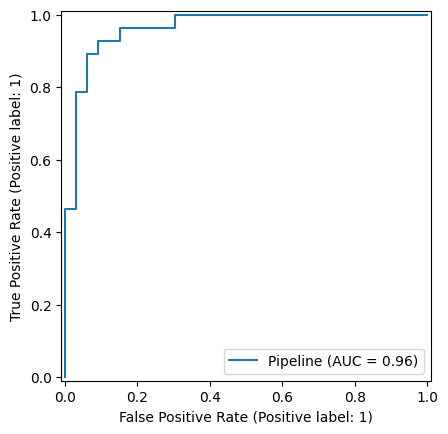

In [6]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_auc_score, RocCurveDisplay)

# 0 = no disease, 1 = disease
X = df[numerical_features + categorical_features]
y = (df["num"] > 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(kernel="rbf", probability=True, random_state=42)),
])

pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)
y_proba = pipeline.predict_proba(X_test)[:, 1]

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification report:")
print(classification_report(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_proba))
RocCurveDisplay.from_estimator(pipeline, X_test, y_test)
plt.show()

### Task 6: Instantiate and train a Decision Tree Classifier (DecisionTreeClassifier) within your pipeline, and evaluate its performance using identical metrics to compare against your SVC model.

**What the code does:**
1. **Imports the tool.** `DecisionTreeClassifier` is the model that makes predictions by asking a series of yes/no questions about the features.
2. **Builds the pipeline.** `tree_pipeline` uses the same preprocessor as the SVC, followed by the Decision Tree. It has its own name so the SVC pipeline is not overwritten.
3. **Trains the model.** `fit` learns from the same training data used for the SVC, so the comparison is fair.
4. **Makes predictions.** `y_pred_tree` holds the predicted classes and `y_proba_tree` holds the predicted probability of disease for each test patient.
5. **Evaluates the model.** It prints the confusion matrix, classification report, and ROC-AUC, and plots the ROC curve, exactly as in Task 5. Using the same test data and metrics makes the results directly comparable.

Confusion matrix:
[[22 11]
 [ 5 23]]

Classification report:
              precision    recall  f1-score   support

           0       0.81      0.67      0.73        33
           1       0.68      0.82      0.74        28

    accuracy                           0.74        61
   macro avg       0.75      0.74      0.74        61
weighted avg       0.75      0.74      0.74        61

ROC-AUC: 0.7440476190476191


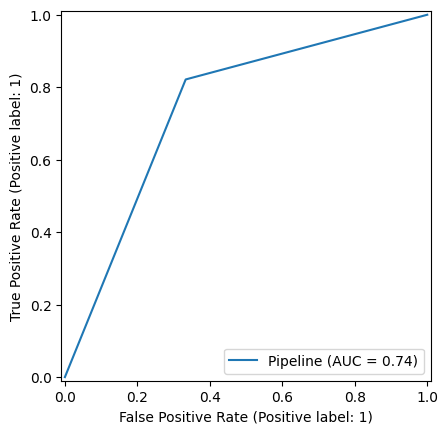

In [7]:
from sklearn.tree import DecisionTreeClassifier

tree_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42)),
])

tree_pipeline.fit(X_train, y_train)

y_pred_tree = tree_pipeline.predict(X_test)
y_proba_tree = tree_pipeline.predict_proba(X_test)[:, 1]

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_tree))

print("\nClassification report:")
print(classification_report(y_test, y_pred_tree))

print("ROC-AUC:", roc_auc_score(y_test, y_proba_tree))
RocCurveDisplay.from_estimator(tree_pipeline, X_test, y_test)
plt.show()

### Task 7: Perform hyperparameter tuning using GridSearchCV on your SVC pipeline (exploring parameters such as C and gamma) to optimize cross-validation performance.

**What the code does:**
1. **Imports the tool.** `GridSearchCV` tries many parameter combinations and picks the best one.
2. **Sets the values to try.** `param_grid` lists the options for `C` (0.1, 1, 10, 100) and `gamma` (`"scale"`, 0.001, 0.01, 0.1, 1). `C` controls how strictly the model fits the training data, and `gamma` controls how far each data point's influence reaches. The `classifier__` prefix tells the search these settings belong to the SVC step in the pipeline.
3. **Sets up the search.** `GridSearchCV` tests all 20 combinations on the SVC pipeline from Task 5:
   - `cv=5` splits the training data into 5 parts, trains on 4, tests on 1, and repeats so each part is used for testing once.
   - `scoring="roc_auc"` uses ROC-AUC to decide which combination is best.
   - `n_jobs=1` runs the search one task at a time.
   - `error_score="raise"` shows an error message if a fit fails instead of hiding it.
4. **Runs the search.** `grid_search.fit(X_train, y_train)` uses only the training data, so the test set stays untouched. This line appears twice, so the search runs twice with the same result.
5. **Shows the results.** `best_params_` is the best combination of `C` and `gamma`, and `best_score_` is its average ROC-AUC across the 5 folds.

In [8]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__gamma": ["scale", 0.001, 0.01, 0.1, 1],
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=1,
    error_score="raise",
)

grid_search.fit(X_train, y_train)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation ROC-AUC:", grid_search.best_score_)

Best parameters: {'classifier__C': 10, 'classifier__gamma': 0.001}
Best cross-validation ROC-AUC: 0.8947490512707903


### Task 8: Generate a decision tree visualization (plot_tree) or inspect feature importances to interpret how the model separates patients with heart disease from healthy patients.

**What the code does:**
1. **Gets the feature names.** After preprocessing, the columns are scaled or split into one-hot columns. `get_feature_names_out()` gives the name of each one. For example, `cat__thal_3.0` means "thal equals 3" and `num__chol` is the scaled cholesterol value.
2. **Gets the importances.** `feature_importances_` shows how much each feature helped the tree make its splits. The values add up to 1, and a higher value means the feature mattered more.
3. **Ranks the features.** The names and importances are combined into a table (`importance_df`) and sorted from highest to lowest.
4. **Prints the top 10.** `importance_df.head(10)` shows the ten most important features.
5. **Plots the top 10.** A horizontal bar chart shows the same ten features so they are easy to compare. `sort_values()` puts the most important feature at the top of the chart.

cat__thal_3.0    0.292921
cat__cp_4.0      0.119427
num__chol        0.110055
num__oldpeak     0.107935
cat__ca_0.0      0.097622
num__age         0.096128
cat__sex_0.0     0.033909
num__trestbps    0.027639
cat__cp_3.0      0.019416
num__thalach     0.018673
dtype: float64


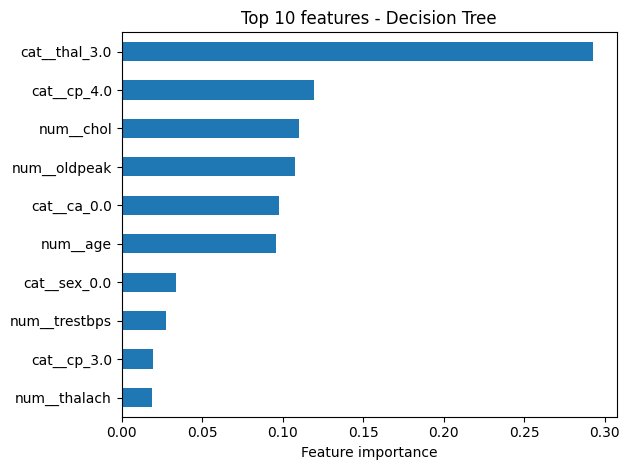

In [9]:
feature_names = tree_pipeline.named_steps["preprocessor"].get_feature_names_out()
importances = tree_pipeline.named_steps["classifier"].feature_importances_

importance_df = (pd.Series(importances, index=feature_names)
                   .sort_values(ascending=False))

print(importance_df.head(10))

importance_df.head(10).sort_values().plot(kind="barh")
plt.xlabel("Feature importance")
plt.title("Top 10 features - Decision Tree")
plt.tight_layout()
plt.show()

#### Task 8 (Supplemental): Decision Tree Visualization

**What the code does:**
1. **Imports the tool.** `plot_tree` draws a Decision Tree as a diagram.
2. **Sets the figure size.** `plt.figure(figsize=(20, 10))` makes the plot large enough to read.
3. **Draws the tree.** `plot_tree` uses the trained tree from Task 6 and the feature names from the importance step above:
   - `feature_names` labels each question with the name of the feature being used.
   - `class_names` labels the two outcomes as "No disease" and "Disease".
   - `filled=True` colors each box by the class it mostly contains.
   - `max_depth=3` shows only the top 3 levels, because the full tree is too large to read. This only affects the picture and does not change the model.
   - `fontsize=9` sets the size of the text in the boxes.
4. **Shows the plot.** `plt.show()` displays the diagram.

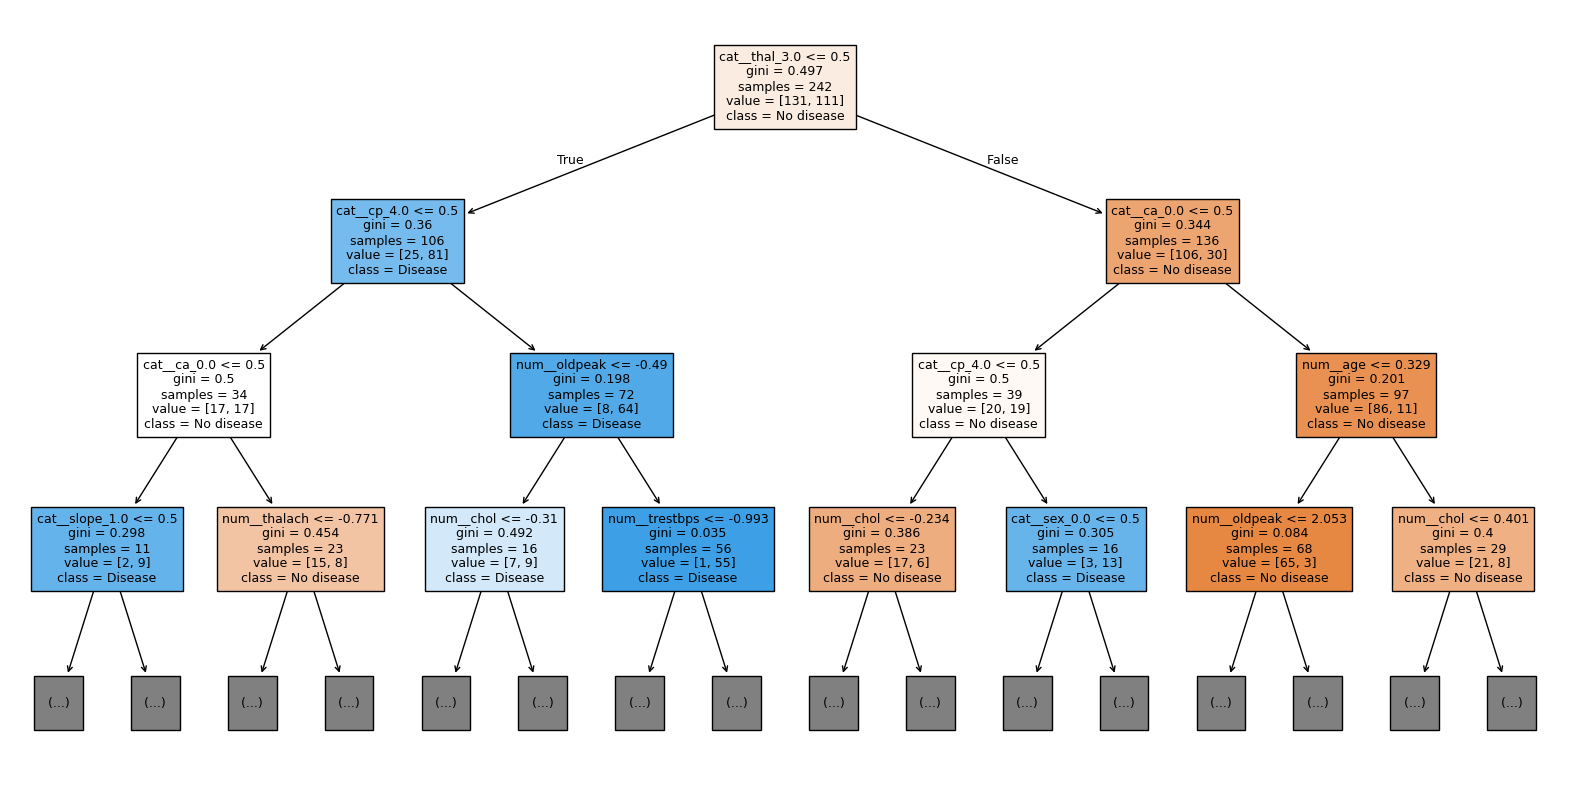

In [11]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(
    tree_pipeline.named_steps["classifier"],
    feature_names=feature_names,
    class_names=["No disease", "Disease"],
    filled=True,
    max_depth=3,
    fontsize=9,
)
plt.show()